# 05 - Final evaluation

Question: how does the chosen model do on the locked-away test set, and where does it go wrong?

The test set is scored once, here, and nowhere else.

In [1]:
import pandas as pd
from lightgbm import LGBMClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

df = pd.read_csv('../data.raw/weatherAUS.csv', parse_dates=['Date'])
d = df.dropna(subset=['RainTomorrow']).copy()
d['y'] = (d['RainTomorrow'] == 'Yes').astype(int)
d['Month'] = d['Date'].dt.month

cat_cols = ['Location', 'WindGustDir', 'WindDir9am', 'WindDir3pm', 'RainToday', 'Month']
num_cols = [c for c in d.select_dtypes('number').columns if c not in ['y', 'Month']]
features = num_cols + cat_cols
d = d.astype({c: 'category' for c in cat_cols})

train_end = d['Date'].quantile(0.8)
val_end = d['Date'].quantile(0.9)
train = d[d['Date'] <= train_end]
val = d[(d['Date'] > train_end) & (d['Date'] <= val_end)]
test = d[d['Date'] > val_end]

gbm = LGBMClassifier(n_estimators=500, learning_rate=0.05, random_state=42, verbose=-1)
gbm.fit(train[features], train['y'])


,learning_rate,0.05
,n_estimators,500
,random_state,42
,verbose,-1
,boosting_type,'gbdt'
,num_leaves,31
,max_depth,-1
,subsample_for_bin,200000
,objective,None
,class_weight,None
,min_split_gain,0.0


In [2]:
def score(name, y_true, y_pred):
    return {
        'threshold': name,
        'accuracy': accuracy_score(y_true, y_pred),
        'precision': precision_score(y_true, y_pred, zero_division=0),
        'recall': recall_score(y_true, y_pred),
        'f1': f1_score(y_true, y_pred),
    }

val_proba = gbm.predict_proba(val[features])[:, 1]

thresholds = [0.2, 0.3, 0.4, 0.5, 0.6, 0.7]
rows = [score(t, val['y'], (val_proba >= t).astype(int)) for t in thresholds]
print(pd.DataFrame(rows).round(3))


   threshold  accuracy  precision  recall     f1
0        0.2     0.806      0.550   0.816  0.657
1        0.3     0.838      0.624   0.729  0.673
2        0.4     0.854      0.691   0.656  0.673
3        0.5     0.861      0.753   0.582  0.656
4        0.6     0.860      0.806   0.509  0.624
5        0.7     0.851      0.853   0.417  0.560


In [3]:
THRESHOLD = 0.4

test_proba = gbm.predict_proba(test[features])[:, 1]
test_pred = (test_proba >= THRESHOLD).astype(int)

final = pd.DataFrame([
    score('always no', test['y'], pd.Series(0, index=test.index)),
    score('same as today', test['y'], (test['RainToday'] == 'Yes').astype(int)),
    score('lightgbm at 0.4', test['y'], test_pred),
]).rename(columns={'threshold': 'model'})
print(final.round(3))


             model  accuracy  precision  recall     f1
0        always no     0.782      0.000   0.000  0.000
1    same as today     0.753      0.433   0.427  0.430
2  lightgbm at 0.4     0.856      0.682   0.631  0.656


In [4]:
errors = test.assign(pred=test_pred)
rainy = errors[errors['y'] == 1]

by_station = pd.DataFrame({
    'rain_rate': errors.groupby('Location')['y'].mean(),
    'rainy_days': rainy.groupby('Location').size(),
    'recall': rainy.groupby('Location')['pred'].mean(),
    'records_sunshine': errors['Sunshine'].notna().groupby(errors['Location']).mean() > 0.5,
}).sort_values('recall')

print(by_station.round(3).head(5))
print(by_station.round(3).tail(5))
print(by_station.groupby('records_sunshine')['recall'].agg(['mean', 'size']).round(3))


              rain_rate  rainy_days  recall  records_sunshine
Location                                                     
AliceSprings      0.090          26   0.346             False
Townsville        0.179          52   0.346             False
Woomera           0.077          22   0.364             False
SalmonGums        0.129          38   0.395             False
Newcastle         0.258          73   0.411             False
              rain_rate  rainy_days  recall  records_sunshine
Location                                                     
Walpole           0.326          94   0.734             False
Darwin            0.395         117   0.761              True
Portland          0.328          97   0.763             False
Cairns            0.354          92   0.783             False
MountGambier      0.271          78   0.821             False
                   mean  size
records_sunshine             
False             0.600    36
True              0.636    13


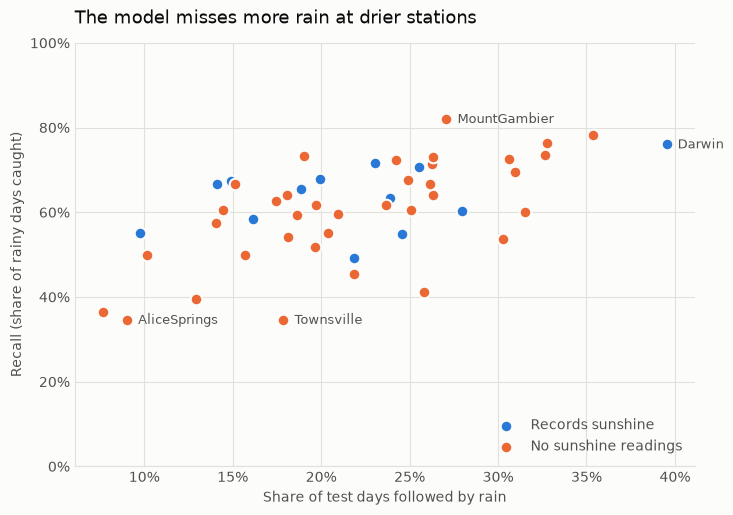

In [5]:
import matplotlib.pyplot as plt
from pathlib import Path

BLUE, ORANGE = '#2a78d6', '#eb6834'
SURFACE, INK, MUTED, GRID = '#fcfcfb', '#0b0b0b', '#52514e', '#e1e0d9'

fig, ax = plt.subplots(figsize=(8, 5.5), facecolor=SURFACE)
ax.set_facecolor(SURFACE)

groups = [(True, BLUE, 'Records sunshine'), (False, ORANGE, 'No sunshine readings')]
for flag, colour, label in groups:
    part = by_station[by_station['records_sunshine'] == flag]
    ax.scatter(part['rain_rate'], part['recall'], s=70, color=colour, label=label,
               edgecolor=SURFACE, linewidth=1.5)

for station in ['AliceSprings', 'Townsville', 'MountGambier', 'Darwin']:
    row = by_station.loc[station]
    ax.annotate(station, (row['rain_rate'], row['recall']), xytext=(8, -3),
                textcoords='offset points', fontsize=9, color=MUTED)

ax.set_title('The model misses more rain at drier stations', loc='left', color=INK, fontsize=13, pad=14)
ax.set_xlabel('Share of test days followed by rain', color=MUTED)
ax.set_ylabel('Recall (share of rainy days caught)', color=MUTED)
ax.xaxis.set_major_formatter('{x:.0%}')
ax.yaxis.set_major_formatter('{x:.0%}')
ax.set_ylim(0, 1)
ax.grid(color=GRID, linewidth=0.8)
ax.set_axisbelow(True)
ax.spines[['top', 'right']].set_visible(False)
ax.spines[['left', 'bottom']].set_color(GRID)
ax.tick_params(colors=MUTED, length=0)
ax.legend(frameon=False, loc='lower right', labelcolor=MUTED)

Path('../figures').mkdir(exist_ok=True)
fig.savefig('../figures/recall_by_station.png', dpi=200, bbox_inches='tight')
plt.show()


Finding: At the 0.4 threshold chosen on validation, LightGBM scores 0.856 accuracy, 0.682 precision, 0.631 recall and F1 0.656 on the test set, against 0.782 accuracy for "always no" and F1 0.430 for "same as today". Recall by station runs from 0.35 to 0.82 and rises with how often it rains there (correlation 0.58).

Why it matters: The model holds up on ten months it never saw, with F1 only 0.017 below validation. The overall score hides weak spots: it misses most of the rain at dry stations, where it had few rainy days to learn from. Stations with Sunshine readings do only slightly better (0.636 recall against 0.600).

Decision: Report the test result at 0.4 as the final number. The threshold was fixed before the test set was scored and is not revisited.

Limit: Per-station recall rests on 22 to 117 rainy days, so single stations are noisy. Only 13 stations record Sunshine in the test period, fewer than earlier years, so what a station reports changed over time. The test period is ten months and has no July or August, the wettest months.